# AF488⁺ cells at and across the junction of WT3 and GD1 assembloids

**Question.** Do assembloids of WT3 and GD1 differ in the number of AF488-labelled (AF488⁺) cells at the junction between the two organoids, in the number that crossed the junction into the partner organoid, and in where the crossed cells lie?

**Sample.** 614 sections that passed the pre-screen and whose junction line was accepted (or redrawn by hand) in the Junction review: **WT3 265 sections on 17 slides, GD1 349 sections on 19 slides**, from three experiments (8, 9 and 10), each with both genotypes. WT2 is listed in the scan file list but is not part of this study; it was left out by design, before any analysis. How the 614 were reached, and how the automated count compares with human counts, is in `01_validation.ipynb`.

**Counting method.** An AF488⁺ cell is one **object of the AF488 mask**: the AF488 channel (brightest plane over z) is smoothed (Gaussian, 0.5 µm), its local background (Gaussian, σ = 20 µm) is subtracted, and the result is thresholded inside the tissue at the median + 5 robust SD (1.4826 × MAD) of the section's tissue; objects smaller than 20 µm² are removed and holes smaller than 10 µm² filled. One connected object counts as one labelled cell body, so no nuclear segmentation or per-cell intensity rule is involved. The junction line and the junction region (the counting band along it) come from the cells-analysis run.

**Where a cell lies** (definitions of 5 Nov 2026). The junction line of each section is extended straight past both its ends (along the direction of its last 60 µm), so that every point of the section lies on one side of it or the other (`sides.py`). The **home side** is the side holding more AF488 mask-object area: the organoid where AF488 is at home. An AF488⁺ object **crossed** when its centroid lies on the other side, the **far side** — however far past the line, and whether or not it lies in the junction region. Every AF488⁺ object that has not crossed is **at home**. Counts are divided by the length of the junction line (per mm). For the crossed objects of a section, the mean distance to the organoid edge (that of the nearest segmented cell) and the mean distance past the line are recorded when the section has at least 3 crossed objects. A negative distance to the edge (the nearest cell lies outside the tissue mask; 95 of the crossed objects) is left out of the edge outcomes, which then need 3 crossed objects with a distance. An earlier version of this analysis counted only objects beside the line and 2–300 µm from it; the two definitions are compared under *Robustness*.

**Statistics.** Sections of one slide are not independent, so every comparison uses a linear mixed model with genotype and experiment as fixed effects and slide as a random intercept (REML; Wald 95 % confidence intervals). Counts per mm are analysed as log(1 + y) and reported as the fold WT3 / GD1; the share crossed and the distances as the difference WT3 − GD1. **Primary outcome: AF488⁺ cells that crossed, per mm of junction.** It was declared primary after exploratory analysis of the same data (`notebooks/dataset/03`–`05`); it was not pre-registered. All other outcomes are secondary, with the Holm correction across the seven of them. Robustness: leaving out one experiment or one slide at a time, a slide-level test (n = slides), adjustment for section covariates, and leaving out the sections whose home side is uncertain.

In [1]:
import ssl

# Some Python installations on Windows cannot read the Windows certificate store.
try:
    ssl.create_default_context()
except ssl.SSLError:  # pragma: no cover - machine-specific
    ssl.SSLContext._load_windows_store_certs = lambda self, storename, purpose: None

import json
import sys
import warnings
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().resolve()
while not (ROOT / "microscopy_viewer").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

# ---------------------------------------------------------------- Settings: change these
DATA = Path(r"D:\Slidescanner extracted")
RUN = DATA / "cells_analysis" / "2026-10-28_090440 re-scored"      # the cells-analysis run (614 sections)
OUT = DATA / "run_analysis_20261028"                                # caches written by notebooks/dataset
MASKS = OUT / "af488_mask"                                          # af488_masks.py: the AF488 mask, every section
FIGURES = OUT / "figures_official"
DESIGN_CSV = DATA / "Image_File_List.csv"
GENOTYPES = ["WT3", "GD1"]       # WT2 is in the file list but not part of this study
CHANNEL = "AF488"
METHOD_MASK = "kmad5"            # the counting method: AF488 mask objects, Gaussian 20 µm background, median + 5 SD
GAP_UM, NEAR_UM = 2.0, 300.0     # the earlier definition of crossed (beside the line, 2–300 µm past it), to compare
# crossed now = anywhere on the far side of the junction line (sides.py: the line extended past its ends)
SEED, N_BOOT = 0, 2000
SAVE_FIGURES = True
# ----------------------------------------------------------------------------------------

FIGURES.mkdir(parents=True, exist_ok=True)

# Publication style: black and greys only for data; images in the stain's own colour.
INK, DARK, MID, LIGHT = "#000000", "#4d4d4d", "#8c8c8c", "#d9d9d9"
GENOTYPE_FACE = {"WT3": DARK, "GD1": "#ffffff"}        # filled vs open, black edge on both
GENOTYPE_MARKER = {"WT3": "o", "GD1": "s"}
mpl.rcParams.update({
    "font.family": "Arial", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "normal",
    "axes.labelsize": 9, "axes.linewidth": 1.0, "axes.edgecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.major.width": 1.0, "ytick.major.width": 1.0, "xtick.major.size": 4, "ytick.major.size": 4,
    "xtick.color": INK, "ytick.color": INK, "axes.prop_cycle": mpl.cycler(color=[INK, MID, DARK, LIGHT]),
    "legend.frameon": False, "legend.fontsize": 8, "figure.dpi": 120,
    "savefig.dpi": 600, "savefig.bbox": "tight", "svg.fonttype": "none", "pdf.fonttype": 42,
})


def save(fig, name):
    """Write the figure as vector (svg, pdf) and 600 dpi png into FIGURES."""
    if SAVE_FIGURES:
        for ext in ("svg", "pdf", "png"):
            fig.savefig(FIGURES / f"{name}.{ext}")


def panel_letters(axes, x=-0.22, y=1.04):
    for letter, ax in zip("abcdefghijklmnop", np.ravel(axes)):
        ax.text(x, y, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", va="bottom")


def p_text(p):
    return "n.s." if not np.isfinite(p) or p >= 0.05 else ("P < 0.001" if p < 0.001 else f"P = {p:.3f}")


design = pd.read_csv(DESIGN_CSV)
design["name"] = design["File_Name"].str.replace(".ome.tiff", "", regex=False)
design = design[design["Genotype"].isin(GENOTYPES)].copy()
design["slide"] = design["Genotype"] + " e" + design["Experiment"].astype(str) + " s" + design["Slide"].astype(str)
design["Experiment"] = design["Experiment"].astype(str)


## Sections, sides and counts

The run's sections are joined to the design table (genotype, experiment, slide). In each section the AF488 mask objects (`af488_mask/<section>/objects.parquet`, mask `kmad5`) and all the run's segmented cells (`cells/<section>.csv`, the whole section) are placed on one side of the extended junction line by `sides.py`, the same way for both tables; the home side is the side with more AF488 mask-object area. (The stored distance columns of the objects and of the cells each took their sign from their own points, and in 4 GD1 sections the two disagreed, so that objects on the home side had been counted as crossed. Taking the side from the line itself removes this.)

**Sections whose home side is uncertain.** As a check, the share of the run's AF488⁺ nuclei within 650 µm of the line that lie on the home side is computed for every section. In the 7 sections listed under the next cell it is below one half: most labelled nuclei near the line lie on the side with less AF488 mask area. Five are from one WT3 slide of experiment 8 (WT3 e8 s4: 021-020_s5, s6, s14, s28, s29; the run flagged "labelled cells on both sides" there), two from one GD1 slide of experiment 10 (GD1 e10 s1: 052-051_s17, s19). Their home side is uncertain; they are kept in the analysis and left out in a sensitivity check of the primary outcome (Figure 2c).

In [2]:
from IPython.display import display
import statsmodels.formula.api as smf
from scipy.spatial import cKDTree
from statsmodels.stats.multitest import multipletests
from statsmodels.tools.sm_exceptions import ConvergenceWarning

warnings.simplefilter("ignore", ConvergenceWarning)   # slide variance near 0 in a few refits: the fit is still valid

# ---------------------------------------------------------------- Settings for this notebook
CACHE = OUT / "cache"            # the run's cells within 650 µm of the line (dataset/03): used only to check the home side
MIN_EDGE = 3                     # a section's distance outcomes need at least this many crossed cells
MIN_SHARE = 5                    # the share crossed needs at least this many AF488+ cells in the section
WIDTH_STEP_UM, WIDTH_MIN_CELLS = 25.0, 20   # local half-width of the organoid, per 25 µm step past the line
REFERENCE, OTHER = "GD1", "WT3"  # every fold and difference is WT3 against GD1
TERM = f"C(Genotype, Treatment('{REFERENCE}'))[T.{OTHER}]"
CELL_COLUMNS = {"Centroid Y (µm)": "y", "Centroid X (µm)": "x", "Distance to the tissue edge (µm)": "edge"}
# ----------------------------------------------------------------------------------------------

sys.path.insert(0, str(ROOT / "notebooks" / "official_analysis"))
import sides  # noqa: E402  (which side of the junction line a point is on: the line extended past its ends)

LINES = {}                       # each section's junction line, µm (y, x)


def read_section(path):
    info = json.loads(path.read_text(encoding="utf-8"))
    line = info["line"]
    LINES[info["sample"]] = np.asarray(json.loads(line) if isinstance(line, str) else line, float)
    return {"name": info["sample"], "region by": info.get("region_by"),
            "junction length (µm)": info.get("junction_length_um", np.nan), "cells in section": info.get("n_cells_section")}


# The analysed sections: those of the cells-analysis run, with their design (genotype, experiment, slide).
sections = pd.DataFrame([read_section(p) for p in sorted((RUN / "cells").glob("*.json"))])
review = pd.read_excel(RUN / "counts.xlsx", sheet_name="Counts")
review = review[review["Channel"] == CHANNEL].set_index("Sample")
sections["QC status"] = sections["name"].map(review["Review status"])
n_run = len(sections)
sections = sections.merge(design[["name", "Genotype", "Experiment", "slide"]], on="name", how="inner").set_index("name")
sections["length (mm)"] = sections["junction length (µm)"] / 1000
sections["QC ok"] = sections["QC status"].eq("ok")
sections["hand-drawn region"] = sections["region by"].eq("by hand")
scales = pd.read_csv(OUT / "section_scales.csv").set_index("name")      # written by dataset/04
sections["assembloid length (µm)"] = scales["assembloid length (µm)"]
areas = pd.read_csv(OUT / "section_tissue_area.csv").set_index("name")  # written by official_analysis/tissue_area.py
sections["tissue area (mm²)"] = areas["tissue area (mm²)"]
print(f"{n_run} sections in the run, {len(sections)} with a WT3 / GD1 design entry, on {sections['slide'].nunique()} slides")
display(sections.groupby(["Genotype", "Experiment"]).agg(sections=("slide", "size"), slides=("slide", "nunique"))
        .unstack("Genotype").fillna(0).astype(int))

# Each section: its AF488 mask objects (the counted cells) and its segmented cells, each placed on one side of the
# junction line by sides.py (the line extended straight past its ends, so every point has a side).
objects, cells = {}, {}
for name in sections.index:
    line = LINES[name]
    o = pd.read_parquet(MASKS / name / "objects.parquet")
    o = o[o["mask"] == METHOD_MASK].reset_index(drop=True)
    raw = sides.raw_side(o[["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy(float), line)
    sign = sides.home_sign(raw, o["Area (µm²)"])          # home: the side holding more AF488 mask-object area
    o["away"] = raw * sign                                 # > 0: past the line, in the organoid where AF488 is not at home
    o["crossed"], o["home"] = o["away"] > 0, o["away"] < 0
    sections.at[name, "sign"] = sign
    objects[name] = o
    # every segmented cell of the section (the run's cell table): its side, and its distance to the tissue edge
    c = pd.read_csv(RUN / "cells" / f"{name}.csv", usecols=list(CELL_COLUMNS), engine="pyarrow").rename(columns=CELL_COLUMNS)
    c["away"] = sides.away(c[["y", "x"]].to_numpy(float), line, sign)
    cells[name] = c
    # A check of the home side: the share of the run's AF488+ nuclei near the line (within 650 µm) on the home side.
    near = pd.read_parquet(CACHE / f"{name}.parquet", columns=["y", "x", "d", "beside", f"{CHANNEL} positive"])
    pos = near[f"{CHANNEL} positive"].to_numpy(bool)
    sections.at[name, "AF488+ nuclei near the line"] = int(pos.sum())
    sections.at[name, "share of them at home"] = (
        (sides.away(near.loc[pos, ["y", "x"]].to_numpy(float), line, sign) < 0).mean() if pos.any() else np.nan)
    # The earlier definition, kept only to compare with: side from the run's AF488+ nuclei beside the line (dataset/04)
    # applied to the objects' stored distances; crossed = beside the line and 2–300 µm past it.
    beside = pos & near["beside"].to_numpy(bool)
    old_sign = -1.0 if beside.sum() >= 5 and np.median(near.loc[beside, "d"]) > 0 else 1.0
    old_away = o["Distance to the junction line (µm)"].to_numpy(float) * old_sign
    sections.at[name, "crossed (earlier definition)"] = int(
        (o["Beside the junction line"].to_numpy(bool) & (old_away > GAP_UM) & (old_away <= NEAR_UM)).sum())

# Sections whose home side is uncertain: most of the run's AF488+ nuclei near the line lie on the other side.
UNCERTAIN = sections.index[sections["share of them at home"] < 0.5].tolist()
print(f"{len(UNCERTAIN)} sections whose home side is uncertain (fewer than half of the run's AF488+ nuclei within "
      "650 µm of the line lie on the side with more AF488 mask area):")
display(sections.loc[UNCERTAIN, ["Genotype", "Experiment", "slide", "AF488+ nuclei near the line",
                                 "share of them at home"]].round(2))


614 sections in the run, 614 with a WT3 / GD1 design entry, on 36 slides


sections      slides    
Genotype        GD1  WT3    GD1 WT3
Experiment                         
10              122  100      6   6
8               111   80      6   5
9               116   85      7   6

7 sections whose home side is uncertain (fewer than half of the run's AF488+ nuclei within 650 µm of the line lie on the side with more AF488 mask area):


,Genotype,Experiment,slide,AF488+ nuclei near the line,share of them at home
name,,,,,
2025_09_26_Asssembloid_021-020_s14,WT3,8,WT3 e8 s4,54.0,0.20
2025_09_26_Asssembloid_021-020_s28,WT3,8,WT3 e8 s4,116.0,0.15
2025_09_26_Asssembloid_021-020_s29,WT3,8,WT3 e8 s4,195.0,0.24
2025_09_26_Asssembloid_021-020_s5,WT3,8,WT3 e8 s4,154.0,0.49
2025_09_26_Asssembloid_021-020_s6,WT3,8,WT3 e8 s4,100.0,0.43
2025_09_26_Asssembloid_052-051_s17,GD1,10,GD1 e10 s1,54.0,0.28
2025_09_26_Asssembloid_052-051_s19,GD1,10,GD1 e10 s1,27.0,0.44


In [3]:
def half_widths(away, edge):
    """Per 25 µm step past the line, over the whole far side: the organoid's half-width there, as the 99th
    percentile of the segmented cells' distance to the edge. Returns the step edges and the widths."""
    steps = np.arange(0, max(np.nanmax(away, initial=0), 0) + 2 * WIDTH_STEP_UM, WIDTH_STEP_UM)
    step = np.digitize(away, steps) - 1
    out = np.full(len(steps) - 1, np.nan)
    for k in range(len(out)):
        here = (away > 0) & (step == k) & (edge > 0)
        if here.sum() >= WIDTH_MIN_CELLS:
            out[k] = np.percentile(edge[here], 99)
    return steps, out


def width_at(away, steps, widths):
    step = np.digitize(away, steps) - 1
    ok = (step >= 0) & (step < len(widths))
    out = np.full(len(away), np.nan)
    out[ok] = widths[step[ok]]
    return out


def section_outcomes(name, s):
    c, o = cells[name], objects[name]
    x = o[o["crossed"]]
    # An object's distance to the organoid edge is that of the nearest segmented cell (cells lie ~10 µm apart).
    _, nearest = cKDTree(c[["y", "x"]].to_numpy()).query(x[["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy())
    edge = c["edge"].to_numpy(float)[nearest] if len(x) else np.array([])
    NEGATIVE_EDGE.append(int((edge < 0).sum()))
    edge = np.where(edge >= 0, edge, np.nan)     # a negative distance to the edge (cell outside the tissue mask) is left out
    steps, widths = half_widths(c["away"].to_numpy(float), c["edge"].to_numpy(float))
    relative = np.clip(edge / width_at(x["away"].to_numpy(), steps, widths), 0, 1) if len(x) else np.array([])
    n_x, n_h, n_r = len(x), int(o["home"].sum()), int(o["In region"].to_numpy(bool).sum())
    for zone in ("crossed", "home"):
        AREAS.append(pd.DataFrame({"Genotype": s["Genotype"], "zone": zone, "area": o.loc[o[zone], "Area (µm²)"]}))
    enough = n_x >= MIN_EDGE
    enough_edge = np.isfinite(edge).sum() >= MIN_EDGE
    return {"total": len(o), "total per 1000 nuclei": 1000 * len(o) / s["cells in section"],
            "tissue area (mm²)": s["tissue area (mm²)"], "total per mm²": len(o) / s["tissue area (mm²)"],
            "crossed": n_x, "home": n_h, "in junction": n_r,
            "in junction per mm": n_r / s["length (mm)"], "crossed per mm": n_x / s["length (mm)"],
            "home per mm": n_h / s["length (mm)"],
            "share crossed": n_x / (n_x + n_h) if n_x + n_h >= MIN_SHARE else np.nan,
            "edge (µm)": np.nanmean(edge) if enough_edge else np.nan,
            "past line (µm)": x["away"].mean() if enough else np.nan,
            "edge ÷ half-width": np.nanmean(relative) if np.isfinite(relative).sum() >= MIN_EDGE else np.nan,
            "past line ÷ assembloid length": x["away"].mean() / s["assembloid length (µm)"] if enough else np.nan,
            "crossed per mm (earlier definition)": s["crossed (earlier definition)"] / s["length (mm)"]}


AREAS, NEGATIVE_EDGE = [], []
obs = pd.DataFrame({name: section_outcomes(name, s) for name, s in sections.iterrows()}).T.astype(float)
obs = sections[["Genotype", "Experiment", "slide", "QC ok", "hand-drawn region", "length (mm)", "cells in section"]].join(obs)
obs["uncertain home side"] = obs.index.isin(UNCERTAIN)
obs.index.name = "name"
print(f"{len(obs)} sections; AF488+ cells (mask objects) counted: {int(obs['in junction'].sum())} in the junction regions, "
      f"{int(obs['crossed'].sum())} crossed, {int(obs['home'].sum())} on the home side "
      f"(earlier definition: {int(sections['crossed (earlier definition)'].sum())} crossed)")
far = pd.concat([objects[n].loc[objects[n]["crossed"], ["away"]].assign(Genotype=sections.at[n, "Genotype"])
                 for n in sections.index])
print(f"crossed objects with a negative distance to the organoid edge, left out of the edge outcomes: {sum(NEGATIVE_EDGE)}")
print("crossed objects: distance past the line (µm), quartiles, and share more than 300 µm past it, by genotype:")
display(far.groupby("Genotype")["away"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]]
        .join(far.groupby("Genotype")["away"].apply(lambda a: (a > NEAR_UM).mean()).rename("> 300 µm")).round(2))
print("object area (µm²), median and quartiles, by genotype and zone:")
display(pd.concat(AREAS).groupby(["Genotype", "zone"])["area"].quantile([0.25, 0.5, 0.75]).unstack().round(1))


614 sections; AF488+ cells (mask objects) counted: 12701 in the junction regions, 22221 crossed, 168677 on the home side (earlier definition: 11102 crossed)


crossed objects with a negative distance to the organoid edge, left out of the edge outcomes: 95
crossed objects: distance past the line (µm), quartiles, and share more than 300 µm past it, by genotype:


,count,25%,50%,75%,> 300 µm
Genotype,,,,,
GD1,8303.0,96.23,233.57,489.24,0.41
WT3,13918.0,85.03,232.19,488.82,0.42


object area (µm²), median and quartiles, by genotype and zone:


0.25  0.50   0.75
Genotype zone                      
GD1      crossed  27.0  38.7   62.3
         home     30.9  49.0   87.0
WT3      crossed  28.4  43.4   81.0
         home     31.6  52.7  103.1

## Results

**Table 1.** WT3 against GD1 for every outcome. Mean ± SEM over sections; effect from the mixed model (fold WT3 / GD1 on log(1 + y) for counts per mm; difference WT3 − GD1 otherwise) with its 95 % CI; P from the model, Holm-adjusted across the seven secondary outcomes. *Crossed*: anywhere on the far side of the junction line; *home*: anywhere on the home side. Distances are in µm; *local half-width* is the organoid's half-width at the same depth past the line (99th percentile of the segmented cells' distance to the edge, in 25 µm steps over the whole far side; 0 = at the surface, ≈ 0.5–1 = towards the middle); *assembloid length* is the length of the assembloid across the line. The distance outcomes need ≥ 3 crossed objects in a section, the share crossed ≥ 5 objects in the section. The table is also saved as `table_1_results.csv`.

In [4]:
# outcome → (scale of the effect, axis label); "fold" = exp of the WT3 − GD1 difference on log(1 + y)
OUTCOMES = {
    "in junction per mm": ("fold", "AF488$^+$ cells in the junction\nregion (per mm of junction)"),
    "crossed per mm": ("fold", "AF488$^+$ cells crossed\n(per mm of junction)"),
    "home per mm": ("fold", "AF488$^+$ cells on the home side\n(per mm of junction)"),
    "share crossed": ("difference", "Share crossed\ncrossed / (crossed + home)"),
    "edge (µm)": ("difference", "Crossed cells: distance to\nthe organoid edge (µm)"),
    "past line (µm)": ("difference", "Crossed cells: distance\npast the line (µm)"),
    "edge ÷ half-width": ("difference", "Crossed cells: distance to the\nedge / local half-width"),
    "past line ÷ assembloid length": ("difference", "Crossed cells: distance past the\nline / assembloid length"),
}
PRIMARY = "crossed per mm"
SECONDARY = [o for o in OUTCOMES if o != PRIMARY]


def mixed(frame, column, kind, extra=""):
    """WT3 against GD1: linear mixed model, experiment fixed (+ *extra*), slide as random intercept, REML, Wald 95 % CI."""
    d = frame.copy()
    y = d[column].astype(float)
    d["y"] = np.log1p(y) if kind == "fold" else np.log(y) if kind == "logfold" else y
    d = d.dropna(subset=["y"])
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)" + extra, d,
                      groups=d["slide"]).fit(reml=True)
    est, (lo, hi) = fit.params[TERM], fit.conf_int().loc[TERM]
    if kind in ("fold", "logfold"):
        est, lo, hi = np.exp(est), np.exp(lo), np.exp(hi)
    return {"effect": est, "CI low": lo, "CI high": hi, "P": fit.pvalues[TERM], "sections": len(d),
            "slides": d["slide"].nunique()}


def effect_text(e, kind, column=""):
    if kind in ("fold", "logfold"):
        return f"{e['effect']:.2f}× ({e['CI low']:.2f}–{e['CI high']:.2f})"
    digits = 0 if "µm" in column else 3
    text = f"{e['effect']:+.{digits}f} ({e['CI low']:+.{digits}f} to {e['CI high']:+.{digits}f})"
    return text.replace("-", "−")


def p_exact(p):
    return "P < 0.001" if p < 0.001 else f"P = {p:.3f}" if p < 0.01 else f"P = {p:.2f}"


rows = []
for outcome, (kind, _) in OUTCOMES.items():
    y = obs[outcome].astype(float)
    row = {"outcome": outcome, "role": "primary" if outcome == PRIMARY else "secondary",
           "effect scale": "fold WT3 / GD1" if kind == "fold" else "difference WT3 − GD1"}
    for g in GENOTYPES:
        v = y[obs["Genotype"] == g].dropna()
        row[f"{g} mean ± SEM"] = f"{v.mean():.3g} ± {v.std(ddof=1) / np.sqrt(len(v)):.2g}"
    rows.append({**row, **mixed(obs, outcome, kind)})
results = pd.DataFrame(rows).set_index("outcome")
second = results["role"] == "secondary"
results["Holm P"] = np.nan
results.loc[second, "Holm P"] = multipletests(results.loc[second, "P"], method="holm")[1]
results["effect (95 % CI)"] = [effect_text(r, OUTCOMES[o][0], o) for o, r in results.iterrows()]
results["n (WT3 / GD1 sections)"] = [
    "{} / {}".format(*[int(obs.loc[obs["Genotype"] == g, o].notna().sum()) for g in GENOTYPES]) for o in results.index]
TABLE = ["role", "effect scale", "WT3 mean ± SEM", "GD1 mean ± SEM", "effect (95 % CI)", "P", "Holm P",
         "n (WT3 / GD1 sections)", "slides"]
display(results[TABLE].style.format({"P": "{:.2g}", "Holm P": "{:.2g}"}, na_rep="—"))
results[TABLE].to_csv(FIGURES / "table_1_results.csv")


,role,effect scale,WT3 mean ± SEM,GD1 mean ± SEM,effect (95 % CI),P,Holm P,n (WT3 / GD1 sections),slides
outcome,,,,,,,,,
in junction per mm,secondary,fold WT3 / GD1,37 ± 2.3,12.6 ± 0.5,2.32× (1.48–3.63),0.00024,0.0012,265 / 349,36
crossed per mm,primary,fold WT3 / GD1,67.1 ± 5.1,22 ± 1,2.30× (1.44–3.68),0.00049,—,265 / 349,36
home per mm,secondary,fold WT3 / GD1,353 ± 11,234 ± 8.3,1.54× (1.27–1.88),1.5e-05,9.2e-05,265 / 349,36
share crossed,secondary,difference WT3 − GD1,0.146 ± 0.0079,0.0979 ± 0.0041,+0.067 (+0.015 to +0.119),0.011,0.033,265 / 349,36
edge (µm),secondary,difference WT3 − GD1,197 ± 4.6,255 ± 5.6,−58 (−89 to −27),0.00028,0.0012,260 / 338,36
past line (µm),secondary,difference WT3 − GD1,287 ± 6.7,272 ± 7.2,+20 (−13 to +54),0.24,0.47,261 / 338,36
edge ÷ half-width,secondary,difference WT3 − GD1,0.44 ± 0.0077,0.525 ± 0.0081,−0.089 (−0.127 to −0.050),8.6e-06,6e-05,260 / 338,36
past line ÷ assembloid length,secondary,difference WT3 − GD1,0.141 ± 0.0032,0.143 ± 0.0034,−0.001 (−0.017 to +0.015),0.92,0.92,261 / 338,36


### Figure 1

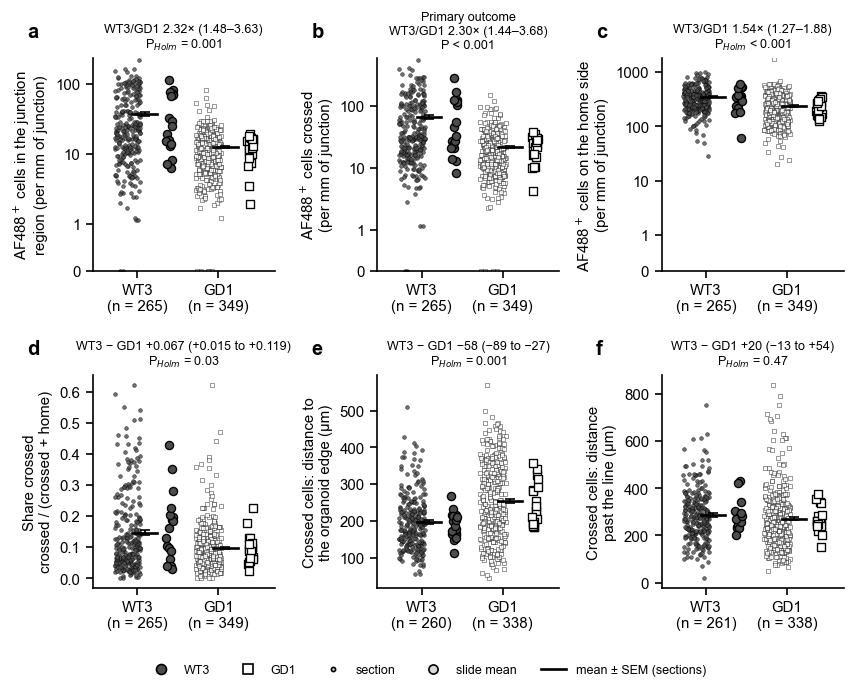

In [5]:
def dot_panel(ax, frame, column, label, kind, e, p, holm, seed=SEED):
    """Sections (small), slide means (large), mean ± SEM (black); the model's effect and P above."""
    rng = np.random.default_rng(seed)
    for k, g in enumerate(GENOTYPES):
        part = frame[frame["Genotype"] == g].dropna(subset=[column])
        y = part[column].astype(float)
        ax.scatter(k - 0.12 + rng.uniform(-0.16, 0.16, len(y)), y, s=5, marker=GENOTYPE_MARKER[g],
                   facecolor=GENOTYPE_FACE[g], edgecolor=INK, linewidth=0.3, alpha=0.8, zorder=2)
        slide_y = part.groupby("slide")[column].mean()
        ax.scatter(k + 0.4 + rng.uniform(-0.04, 0.04, len(slide_y)), slide_y, s=24, marker=GENOTYPE_MARKER[g],
                   facecolor=GENOTYPE_FACE[g], edgecolor=INK, linewidth=0.8, zorder=3)
        m, sem = y.mean(), y.std(ddof=1) / np.sqrt(len(y))
        ax.errorbar(k + 0.09, m, yerr=sem, fmt="none", ecolor=INK, elinewidth=1.2, capsize=3, zorder=4)
        ax.plot([k - 0.06, k + 0.24], [m, m], color=INK, lw=1.6, zorder=4)
    n = [int(frame.loc[frame["Genotype"] == g, column].notna().sum()) for g in GENOTYPES]
    ax.set_xticks([0, 1], [f"{g}\n(n = {a})" for g, a in zip(GENOTYPES, n)])
    ax.set_xlim(-0.55, 1.7)
    ax.set_ylabel(label)
    if kind == "logfold":
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(mpl.ticker.FixedLocator([0.1, 0.2, 0.5, 1, 2, 5, 10]))
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    if kind == "fold":
        ax.set_yscale("symlog", linthresh=1, linscale=0.6)
        ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
        ax.set_ylim(bottom=0)
    head = ("WT3/GD1 " if kind in ("fold", "logfold") else "WT3 − GD1 ") + effect_text(e, kind, column)
    ptxt = p_exact(p) if holm is None or not np.isfinite(holm) else p_exact(holm).replace("P", "P$_{Holm}$")
    lead = "Primary outcome\n" if column == PRIMARY else ""
    ax.set_title(f"{lead}{head}\n{ptxt}", fontsize=7.5, loc="center", fontweight="normal")


FIG1 = ["in junction per mm", "crossed per mm", "home per mm", "share crossed", "edge (µm)", "past line (µm)"]
fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.6))
for ax, outcome in zip(axes.flat, FIG1):
    r = results.loc[outcome]
    kind, label = OUTCOMES[outcome]
    dot_panel(ax, obs, outcome, label, kind, r, r["P"], r["Holm P"])
handles = [mpl.lines.Line2D([], [], ls="", marker=GENOTYPE_MARKER[g], markerfacecolor=GENOTYPE_FACE[g],
                            markeredgecolor=INK, label=g) for g in GENOTYPES]
handles += [mpl.lines.Line2D([], [], ls="", marker="o", ms=2.5, markerfacecolor=LIGHT, markeredgecolor=INK,
                             label="section"),
            mpl.lines.Line2D([], [], ls="", marker="o", ms=5.5, markerfacecolor=LIGHT, markeredgecolor=INK,
                             label="slide mean"),
            mpl.lines.Line2D([], [], color=INK, lw=1.6, label="mean ± SEM (sections)")]
fig.legend(handles=handles, loc="lower center", ncol=5, bbox_to_anchor=(0.5, -0.03), fontsize=7.5)
panel_letters(axes, x=-0.36, y=1.08)
fig.tight_layout(rect=(0, 0.03, 1, 1), h_pad=1.6)
save(fig, "figure_1_wt3_vs_gd1")
plt.show()


**Figure 1. WT3 assembloids have more AF488⁺ cells at and across the junction than GD1 assembloids, a larger share of their AF488⁺ cells crossed, and their crossed cells lie nearer the organoid surface.** (**a**) AF488⁺ cells in the junction region per mm of junction line. (**b**) AF488⁺ cells that crossed the junction (anywhere on the far side of the line, in the partner organoid) per mm — the primary outcome. (**c**) AF488⁺ cells on the home side (anywhere) per mm. (**d**) Share of a section's AF488⁺ cells that crossed, crossed / (crossed + home). (**e**) Mean distance of a section's crossed cells to the organoid edge. (**f**) Mean distance of a section's crossed cells past the line. Small markers: sections (WT3 filled, GD1 open); large markers: slide means; black: mean ± SEM of sections. Counts on a symmetric log axis (linear below 1). Above each panel: fold WT3 / GD1 (a–c) or difference WT3 − GD1 (d–f) with 95 % CI from the linear mixed model (genotype and experiment fixed, slide random; counts as log(1 + y)); P unadjusted for the primary outcome (b), Holm-adjusted across the seven secondary outcomes otherwise. n = sections (265 WT3 / 349 GD1 on 17 / 19 slides; fewer in e and f, which need ≥ 3 crossed cells).

**What it shows (5 Nov 2026).**
- **Primary outcome.** WT3 sections had 67.1 ± 5.1 crossed AF488⁺ cells per mm of junction against 22.0 ± 1.0 in GD1: **2.30-fold (95 % CI 1.44–3.68), P < 0.001**. Crossed cells lie far into the partner organoid: the median crossed object is 232 µm (WT3) and 234 µm (GD1) past the line, and 42 % and 41 % lie more than 300 µm past it.
- **At the junction and on the home side.** WT3 had 2.32-fold (1.48–3.63) more AF488⁺ cells in the junction region (Holm P = 0.001) and 1.54-fold (1.27–1.88) more on the home side (Holm P < 0.001). The excess of crossed cells is larger than the excess at home.
- **Share crossed.** A larger share of the AF488⁺ cells had crossed in WT3: 0.146 against 0.098, difference +0.067 (+0.015 to +0.119), Holm P = 0.03.
- **Where the crossed cells lie.** WT3's crossed cells were 58 µm (27–89) nearer the organoid edge (197 against 255 µm; Holm P = 0.001), also relative to the organoid's local half-width (0.44 against 0.53; −0.089, −0.127 to −0.050; Holm P < 0.001). They lay as far past the line as GD1's: 287 against 272 µm, +20 µm (−13 to +54), Holm P = 0.47; relative to the assembloid length 0.141 against 0.143, −0.001 (−0.017 to +0.015), Holm P = 0.92.

### Figure S1 | Total AF488⁺ cells detected per section

Every AF488⁺ cell the mask finds in the section, wherever it lies (home organoid, junction or the other organoid), and the same per 1,000 segmented nuclei of the section, which corrects for the size of the section. These totals are descriptive: they are not among the pre-declared outcomes and are not in the Holm family. Same model as Table 1 (log(1 + y), genotype and experiment fixed, slide random).

,WT3 mean ± SEM,GD1 mean ± SEM,WT3 median,GD1 median,effect (95 % CI),P,sections,slides
total,367.1 ± 9.1,268.3 ± 8.5,343,236.0,1.49× (1.18–1.89),0.00074,614.000000,36.000000
total per 1000 nuclei,9.991 ± 0.31,7.652 ± 0.19,9,7.2,1.26× (1.05–1.52),0.012,614.000000,36.000000


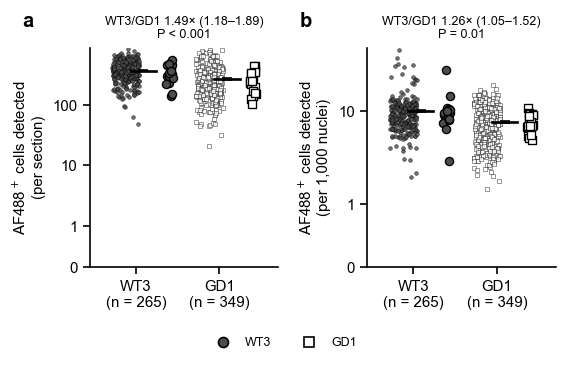

In [6]:
# Descriptive, not part of the pre-declared outcomes (so not in the Holm family): every AF488+ cell the
# mask finds in the section, wherever it lies, and the same per 1 000 segmented nuclei, which corrects for section size.
TOTALS = {"total": "AF488$^+$ cells detected\n(per section)",
          "total per 1000 nuclei": "AF488$^+$ cells detected\n(per 1,000 nuclei)"}
total_effects = pd.DataFrame({column: mixed(obs, column, "fold") for column in TOTALS}).T
for column in TOTALS:
    for g in GENOTYPES:
        v = obs.loc[obs["Genotype"] == g, column].astype(float)
        total_effects.loc[column, f"{g} mean ± SEM"] = f"{v.mean():.4g} ± {v.std(ddof=1) / np.sqrt(len(v)):.2g}"
        total_effects.loc[column, f"{g} median"] = v.median()
total_effects["effect (95 % CI)"] = [effect_text(r, "fold") for _, r in total_effects.iterrows()]
display(total_effects[["WT3 mean ± SEM", "GD1 mean ± SEM", "WT3 median", "GD1 median", "effect (95 % CI)", "P",
                       "sections", "slides"]].style.format({"P": "{:.2g}", "WT3 median": "{:.0f}",
                                                             "GD1 median": "{:.1f}"}))

fig, axes = plt.subplots(1, 2, figsize=(4.8, 2.9))
for ax, (column, label) in zip(axes, TOTALS.items()):
    dot_panel(ax, obs, column, label, "fold", total_effects.loc[column], total_effects.loc[column, "P"], None)
handles = [mpl.lines.Line2D([], [], ls="", marker=GENOTYPE_MARKER[g], markerfacecolor=GENOTYPE_FACE[g],
                            markeredgecolor=INK, label=g) for g in GENOTYPES]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06), fontsize=7.5)
panel_letters(axes, x=-0.36, y=1.08)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "figure_s1_total_af488_cells")
plt.show()
total_effects.to_csv(FIGURES / "table_s1_total_af488_cells.csv")


**What it shows.** The mask detects more AF488⁺ cells in WT3 sections than in GD1 sections: 367 ± 9 against 268 ± 9 per section (mean ± SEM; medians 343 and 236), **1.49-fold (95 % CI 1.18–1.89, P < 0.001)**. Part of this is section size: per 1,000 segmented nuclei the difference is smaller, 10.0 ± 0.3 against 7.7 ± 0.2, **1.26-fold (1.05–1.52, P = 0.01)**. WT3 sections therefore hold more labelled cells overall. The excess in the junction region and of crossed cells (Figure 1a, b; 2.3-fold) is larger than this overall excess; the excess on the home side (Figure 1c, 1.54-fold) is about the same.

### Figure S2 | Assembloid area per section

The area of the tissue in each section (the assembloid as cut), from the nuclear stain: the same tissue mask the AF488 count is thresholded in (Otsu at 1/8 resolution, closed, holes filled; `tissue_area.py`). Then the AF488⁺ cells detected per mm² of it. Descriptive, not in the Holm family. Area is modelled on log(y), counts per mm² on log(1 + y); genotype and experiment fixed, slide random.

,WT3 mean ± SEM,GD1 mean ± SEM,WT3 median,GD1 median,effect (95 % CI),P,sections,slides
tissue area (mm²),2.14 ± 0.051,1.89 ± 0.035,1.98,1.92,1.19× (0.96–1.49),0.12,614.000000,36.000000
total per mm²,177 ± 3,142 ± 3.1,175,140,1.27× (1.11–1.45),0.00057,614.000000,36.000000


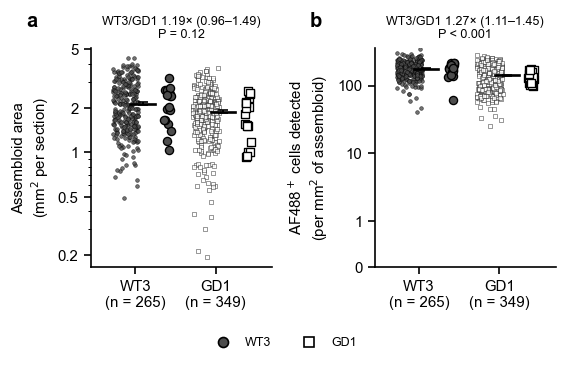

In [7]:
# Descriptive, like Figure S1: the area of the tissue (the assembloid) in each section, from the nuclear stain
# (the tissue mask the AF488 count is thresholded in), and the AF488+ cells detected per mm² of it.
AREA = {"tissue area (mm²)": ("logfold", "Assembloid area\n(mm$^2$ per section)"),
        "total per mm²": ("fold", "AF488$^+$ cells detected\n(per mm$^2$ of assembloid)")}
area_effects = pd.DataFrame({column: mixed(obs, column, kind) for column, (kind, _) in AREA.items()}).T
for column in AREA:
    for g in GENOTYPES:
        v = obs.loc[obs["Genotype"] == g, column].astype(float)
        area_effects.loc[column, f"{g} mean ± SEM"] = f"{v.mean():.3g} ± {v.std(ddof=1) / np.sqrt(len(v)):.2g}"
        area_effects.loc[column, f"{g} median"] = v.median()
area_effects["effect (95 % CI)"] = [effect_text(r, AREA[c][0]) for c, r in area_effects.iterrows()]
display(area_effects[["WT3 mean ± SEM", "GD1 mean ± SEM", "WT3 median", "GD1 median", "effect (95 % CI)", "P",
                      "sections", "slides"]].style.format({"P": "{:.2g}", "WT3 median": "{:.3g}", "GD1 median": "{:.3g}"}))

fig, axes = plt.subplots(1, 2, figsize=(4.8, 2.9))
for ax, (column, (kind, label)) in zip(axes, AREA.items()):
    dot_panel(ax, obs, column, label, kind, area_effects.loc[column], area_effects.loc[column, "P"], None)
handles = [mpl.lines.Line2D([], [], ls="", marker=GENOTYPE_MARKER[g], markerfacecolor=GENOTYPE_FACE[g],
                            markeredgecolor=INK, label=g) for g in GENOTYPES]
fig.legend(handles=handles, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.06), fontsize=7.5)
panel_letters(axes, x=-0.36, y=1.08)
fig.tight_layout(rect=(0, 0.04, 1, 1))
save(fig, "figure_s2_assembloid_area")
plt.show()
area_effects.to_csv(FIGURES / "table_s2_assembloid_area.csv")


**What it shows.** The sections of the two genotypes are about the same size: 2.14 ± 0.05 mm² of assembloid per WT3 section against 1.89 ± 0.04 mm² per GD1 section (medians 1.98 and 1.92 mm²), **1.19-fold (95 % CI 0.96–1.49, P = 0.12)**. Per mm² of assembloid the mask detects more AF488⁺ cells in WT3: 177 ± 3 against 142 ± 3 per mm², **1.27-fold (1.11–1.45, P < 0.001)** — the same excess as per 1,000 nuclei (Figure S1b, 1.26-fold). The larger number of AF488⁺ cells in WT3 sections is therefore a higher density of labelled cells, not larger sections.

### Figure S3 | Assembloid area per section, slide by slide

Each column is one slide (WT3 left, GD1 right, grouped by experiment); each marker one section (WT3 filled circles, GD1 open squares), the bar its slide's median. Log scale. A slide made of much larger or smaller assembloids than the others would stand out here.

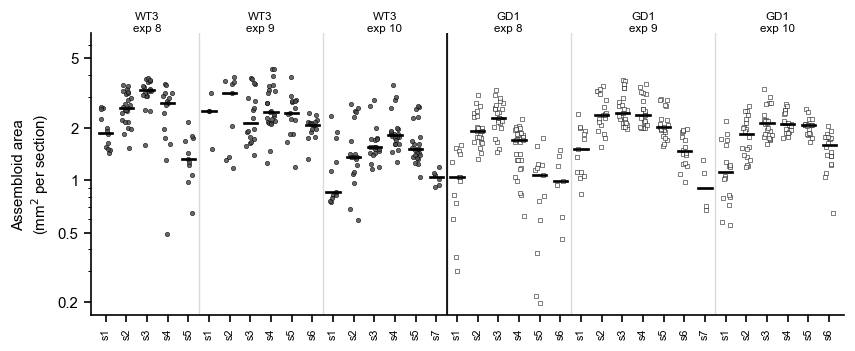

,Genotype,Experiment,sections,median_area,q1,q3
slide,,,,,,
WT3 e8 s1,WT3,8,12,1.87,1.54,2.31
WT3 e8 s2,WT3,8,24,2.61,2.20,3.14
WT3 e8 s3,WT3,8,18,3.28,3.04,3.63
WT3 e8 s4,WT3,8,15,2.78,1.86,3.09
WT3 e8 s5,WT3,8,11,1.33,1.15,1.72
WT3 e9 s1,WT3,9,4,2.49,2.24,2.66
WT3 e9 s2,WT3,9,9,3.16,1.35,3.64
WT3 e9 s3,WT3,9,18,2.12,1.73,2.93
WT3 e9 s4,WT3,9,23,2.46,2.18,3.28


median assembloid area (mm²) by genotype and experiment:


Experiment,10,8,9
Genotype,,,
WT3,1.51,2.55,2.27
GD1,1.86,1.69,2.09


WT3: Spearman ρ (assembloid area, crossed per mm) = 0.23, P = 0.00019, n = 265
GD1: Spearman ρ (assembloid area, crossed per mm) = 0.46, P = 4.9e-20, n = 349
primary outcome adjusted for log assembloid area: fold 2.01 (1.27–3.17), P = 0.0029


In [8]:
# Every slide's sections: is one slide (or one experiment) made of much larger or smaller assembloids?
def slide_order(frame):
    # slides grouped by genotype (WT3 first), then experiment, then slide number
    keys = frame.groupby("slide").agg(Genotype=("Genotype", "first"), Experiment=("Experiment", "first"))
    keys["g"] = keys["Genotype"].map({g: i for i, g in enumerate(GENOTYPES)})
    keys["e"] = keys["Experiment"].astype(int)
    keys["s"] = [int(name.rsplit("s", 1)[-1]) for name in keys.index]
    return keys.sort_values(["g", "e", "s"])


AREA_COLUMN = "tissue area (mm²)"
order = slide_order(obs)
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(7.2, 3.0))
for i, (slide, k) in enumerate(order.iterrows()):
    y = obs.loc[obs["slide"] == slide, AREA_COLUMN].astype(float)
    g = k["Genotype"]
    ax.scatter(i + rng.uniform(-0.22, 0.22, len(y)), y, s=7, marker=GENOTYPE_MARKER[g], facecolor=GENOTYPE_FACE[g],
               edgecolor=INK, linewidth=0.35, alpha=0.85, zorder=2)
    ax.plot([i - 0.32, i + 0.32], [y.median()] * 2, color=INK, lw=1.6, zorder=3)
ax.set_yscale("log")
ax.yaxis.set_major_locator(mpl.ticker.FixedLocator([0.2, 0.5, 1, 2, 5]))
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_ylabel("Assembloid area\n(mm$^2$ per section)")
ax.set_xticks(range(len(order)), [f"s{k['s']}" for _, k in order.iterrows()], fontsize=6.5, rotation=90)
ax.set_xlim(-0.7, len(order) - 0.3)
# genotype × experiment blocks: a thin divider and a label above
blocks = order.reset_index().groupby(["Genotype", "Experiment"], sort=False).apply(lambda b: (b.index.min(), b.index.max()))
top = obs[AREA_COLUMN].max() * 1.6
for (g, e), (a, b) in blocks.items():
    if a > 0:
        ax.axvline(a - 0.5, color=LIGHT if (g, e) != (GENOTYPES[1], blocks.index[0][1]) else MID, lw=0.8, zorder=1)
    ax.text((a + b) / 2, top, f"{g}\nexp {e}", ha="center", va="bottom", fontsize=7)
ax.set_ylim(top=top * 1.0)
first_gd1 = next(i for i, (_, k) in enumerate(order.iterrows()) if k["Genotype"] == GENOTYPES[1])
ax.axvline(first_gd1 - 0.5, color=INK, lw=1.0, zorder=1)
fig.tight_layout()
save(fig, "figure_s3_assembloid_area_per_slide")
plt.show()

per_slide = (obs.groupby("slide").agg(Genotype=("Genotype", "first"), Experiment=("Experiment", "first"),
                                      sections=(AREA_COLUMN, "size"), median_area=(AREA_COLUMN, "median"),
                                      q1=(AREA_COLUMN, lambda v: v.quantile(0.25)),
                                      q3=(AREA_COLUMN, lambda v: v.quantile(0.75)))
             .loc[order.index].round(2))
display(per_slide)
per_slide.to_csv(FIGURES / "table_s3_assembloid_area_per_slide.csv")
by_block = obs.groupby(["Genotype", "Experiment"])[AREA_COLUMN].median().unstack("Experiment").loc[GENOTYPES].round(2)
print("median assembloid area (mm²) by genotype and experiment:")
display(by_block)

# Does assembloid size go with the primary outcome, and does it account for part of the genotype difference?
for g in GENOTYPES:
    part = obs[obs["Genotype"] == g]
    rho = stats.spearmanr(part[AREA_COLUMN], part["crossed per mm"])
    print(f"{g}: Spearman ρ (assembloid area, crossed per mm) = {rho.correlation:.2f}, P = {rho.pvalue:.2g}, "
          f"n = {len(part)}")
by_area = mixed(obs.assign(log_area=np.log(obs[AREA_COLUMN].astype(float))), "crossed per mm", "fold", " + log_area")
print(f"primary outcome adjusted for log assembloid area: fold {by_area['effect']:.2f} "
      f"({by_area['CI low']:.2f}–{by_area['CI high']:.2f}), P = {by_area['P']:.2g}")


**What it shows.** Section size varies more between slides than between genotypes. Slide medians run from 0.85 to 3.28 mm² in WT3 and from 0.91 to 2.44 mm² in GD1, and within a slide the sections span about a factor of two. Experiment matters more than genotype: WT3 experiments 8 and 9 have the largest assembloids (median 2.55 and 2.27 mm²) and WT3 experiment 10 the smallest (1.51 mm²), while GD1 is more even (1.69, 2.09 and 1.86 mm² in experiments 8, 9 and 10). No single slide stands out from the others of its experiment. Small sections (< 0.5 mm²) occur mostly on a few GD1 slides (experiment 8, slides 1, 5 and 6), probably sections cut near the end of the assembloid. Because larger assembloids have more crossed AF488⁺ cells per mm in both genotypes (Spearman ρ 0.23 in WT3 and 0.46 in GD1), the larger WT3 assembloids of experiments 8 and 9 add to the WT3 excess; adjusting for log assembloid area lowers the primary fold from 2.30× to 2.01× (1.27–3.17, P = 0.003).

## Robustness of the primary outcome

Five checks on crossed AF488⁺ cells per mm, each refitting the mixed model: (a) leaving out one experiment at a time, and each experiment on its own (genotype only, slide random); (b) leaving out one slide at a time (36 refits); (c) adding section covariates — the Junction review's QC status ("ok" against "check" / "fail", from `counts.xlsx`), whether the junction region was drawn by hand (`region_by`), log junction length and log number of segmented cells in the section — one at a time and all together, within each QC stratum, and without the 7 sections whose home side is uncertain; (d) with slides as the unit: each slide's mean of log(1 + crossed per mm), WT3 against GD1 by Welch's t-test (fold = ratio of the geometric means of 1 + y) and the Mann–Whitney test, and an ordinary regression of the slide means on genotype and experiment. Last, for comparison only, the primary outcome under the earlier definition of crossed (beside the line, 2–300 µm past it, side from the run's AF488⁺ nuclei).

Primary outcome (crossed per mm), WT3 / GD1 — by experiment:


,effect,CI low,CI high,P,sections,slides
model,,,,,,
all experiments,2.304,1.441,3.683,0.000,614,36
without experiment 8,2.534,1.481,4.335,0.001,423,25
without experiment 9,1.371,0.784,2.395,0.268,413,23
without experiment 10,3.451,1.946,6.121,0.000,392,24
experiment 8 alone,1.856,0.707,4.874,0.209,191,11
experiment 9 alone,5.910,3.595,9.714,0.000,201,13
experiment 10 alone,1.046,0.571,1.916,0.884,222,12


leave one slide out: fold 2.11–2.55, P ≤ 0.0014, P < 0.05 in 36 of 36
Slides as the unit (n = slides):


,primary outcome
fold (Welch),2.274737
CI low,1.26584
CI high,4.087742
Welch P,0.008129
Mann-Whitney P,0.017475
fold (OLS + experiment),2.305917
OLS P,0.001762
slides WT3 / GD1,17 / 19


Primary outcome adjusted for section covariates, within QC strata, and without the sections whose home side is uncertain:


,effect,CI low,CI high,P,sections,slides
model,,,,,,
unadjusted,2.304,1.441,3.683,0.000,614,36
+ QC status (ok),2.255,1.411,3.604,0.001,614,36
+ hand-drawn region,2.295,1.435,3.671,0.001,614,36
+ log junction length,2.269,1.425,3.611,0.001,614,36
+ log cells per section,2.108,1.340,3.317,0.001,614,36
+ all four,1.715,1.146,2.568,0.009,614,36
QC status ok only,1.537,0.838,2.819,0.164,170,25
QC status check / fail only,2.728,1.583,4.701,0.000,444,36
without uncertain home side (7),2.282,1.431,3.639,0.001,607,36


The uncertain sections by genotype: {'WT3': 5, 'GD1': 2}
Primary outcome under the two definitions of crossed:


,effect,CI low,CI high,P,sections,slides,WT3 mean,GD1 mean
definition,,,,,,,,
crossed: anywhere on the far side (this notebook),2.304,1.441,3.683,0.000,614,36,67.108,21.997
"crossed: beside the line, 2–300 µm past it (earlier)",1.864,1.284,2.707,0.001,614,36,29.681,11.659


Covariates by genotype (share of sections, or mean):


,qc,hand,length (mm),cells in section
Genotype,,,,
GD1,0.163,0.235,1.095,36669.458
WT3,0.426,0.343,0.980,41846.053


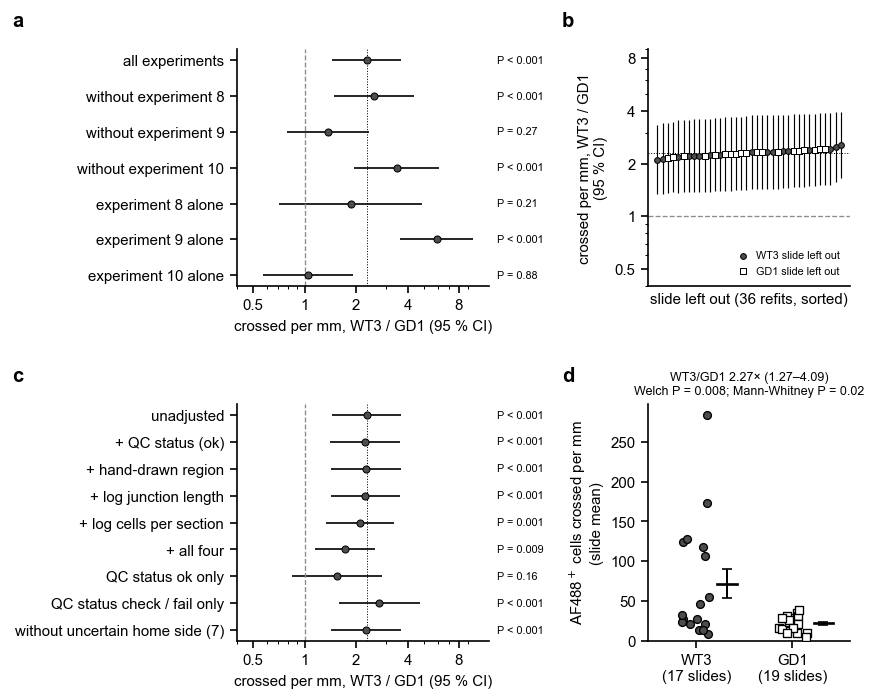

In [9]:
def primary_fit(frame, extra=""):
    return mixed(frame, PRIMARY, "fold", extra)


# (a) experiments: all, each left out, each alone
rows = [{"model": "all experiments", **primary_fit(obs)}]
for e in sorted(obs["Experiment"].unique(), key=int):
    rows.append({"model": f"without experiment {e}", **primary_fit(obs[obs["Experiment"] != e])})
for e in sorted(obs["Experiment"].unique(), key=int):
    part = obs[obs["Experiment"] == e]
    d = part.assign(y=np.log1p(part[PRIMARY]))
    fit = smf.mixedlm(f"y ~ C(Genotype, Treatment('{REFERENCE}'))", d, groups=d["slide"]).fit(reml=True)
    lo, hi = np.exp(fit.conf_int().loc[TERM])
    rows.append({"model": f"experiment {e} alone", "effect": np.exp(fit.params[TERM]), "CI low": lo, "CI high": hi,
                 "P": fit.pvalues[TERM], "sections": len(d), "slides": d["slide"].nunique()})
by_experiment = pd.DataFrame(rows).set_index("model")
print("Primary outcome (crossed per mm), WT3 / GD1 — by experiment:")
display(by_experiment.round(3))

# (b) leave one slide out
loso = pd.DataFrame([{"left out": sl, "Genotype": sl.split(" ")[0], **primary_fit(obs[obs["slide"] != sl])}
                     for sl in sorted(obs["slide"].unique())])
print(f"leave one slide out: fold {loso['effect'].min():.2f}–{loso['effect'].max():.2f}, "
      f"P ≤ {loso['P'].max():.2g}, P < 0.05 in {int((loso['P'] < 0.05).sum())} of {len(loso)}")

# (c) slides as the unit: each slide's mean of log(1 + crossed per mm)
slide_means = (obs.assign(t=np.log1p(obs[PRIMARY])).groupby("slide")
               .agg(t=("t", "mean"), mean=(PRIMARY, "mean"), Genotype=("Genotype", "first"),
                    Experiment=("Experiment", "first"), sections=("t", "size")))
a, b = (slide_means.loc[slide_means["Genotype"] == g, "t"] for g in (OTHER, REFERENCE))
welch = stats.ttest_ind(a, b, equal_var=False)
va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
half = stats.t.ppf(0.975, dof) * np.sqrt(va + vb)
ols = smf.ols(f"t ~ C(Genotype, Treatment('{REFERENCE}')) + C(Experiment)", slide_means).fit()
slide_level = {"fold (Welch)": np.exp(a.mean() - b.mean()), "CI low": np.exp(a.mean() - b.mean() - half),
               "CI high": np.exp(a.mean() - b.mean() + half), "Welch P": welch.pvalue,
               "Mann-Whitney P": stats.mannwhitneyu(a, b).pvalue,
               "fold (OLS + experiment)": np.exp(ols.params[TERM]), "OLS P": ols.pvalues[TERM],
               "slides WT3 / GD1": f"{len(a)} / {len(b)}"}
print("Slides as the unit (n = slides):")
display(pd.Series(slide_level).to_frame("primary outcome"))

# (d) section covariates added to the model
cov = obs.assign(qc=obs["QC ok"].astype(int), hand=obs["hand-drawn region"].astype(int),
                 log_length=np.log(obs["length (mm)"].astype(float)),
                 log_cells=np.log(obs["cells in section"].astype(float)))
ADJUST = {"unadjusted": "", "+ QC status (ok)": " + qc", "+ hand-drawn region": " + hand",
          "+ log junction length": " + log_length", "+ log cells per section": " + log_cells",
          "+ all four": " + qc + hand + log_length + log_cells"}
adjusted = pd.DataFrame([{"model": k, **primary_fit(cov, v)} for k, v in ADJUST.items()]
                        + [{"model": "QC status ok only", **primary_fit(cov[cov["QC ok"]])},
                           {"model": "QC status check / fail only", **primary_fit(cov[~cov["QC ok"]])},
                           {"model": f"without uncertain home side ({len(UNCERTAIN)})",
                            **primary_fit(cov[~cov["uncertain home side"]])}]).set_index("model")
print("Primary outcome adjusted for section covariates, within QC strata, and without the sections whose home side "
      "is uncertain:")
display(adjusted.round(3))
print("The uncertain sections by genotype:", obs.loc[UNCERTAIN, "Genotype"].value_counts().to_dict())

# For comparison only: the primary outcome under the earlier definition (beside the line, 2–300 µm past it, side
# from the run's AF488+ nuclei and the objects' stored distances).
earlier = pd.DataFrame([{"definition": "crossed: anywhere on the far side (this notebook)", **primary_fit(obs)},
                        {"definition": "crossed: beside the line, 2–300 µm past it (earlier)",
                         **mixed(obs, "crossed per mm (earlier definition)", "fold")}]).set_index("definition")
for g in GENOTYPES:
    part = obs[obs["Genotype"] == g]
    earlier.loc[earlier.index[0], f"{g} mean"] = part[PRIMARY].mean()
    earlier.loc[earlier.index[1], f"{g} mean"] = part["crossed per mm (earlier definition)"].mean()
print("Primary outcome under the two definitions of crossed:")
display(earlier.round(3))
cov_by_genotype = cov.groupby("Genotype")[["qc", "hand", "length (mm)", "cells in section"]].mean()
print("Covariates by genotype (share of sections, or mean):")
display(cov_by_genotype.round(3))


def forest(ax, table, labels=None):
    ys = np.arange(len(table))[::-1]
    ax.hlines(ys, table["CI low"], table["CI high"], color=INK, lw=1.0)
    ax.scatter(table["effect"], ys, s=18, marker="o", facecolor=DARK, edgecolor=INK, linewidth=0.6, zorder=3)
    ax.axvline(1, color=MID, lw=0.8, ls="--")
    ax.axvline(table["effect"].iloc[0], color=INK, lw=0.6, ls=":")
    ax.set_yticks(ys, labels if labels is not None else table.index)
    ax.set_xscale("log")
    ax.set_xticks([0.5, 1, 2, 4, 8])
    ax.xaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
    ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlim(0.4, 12)
    ax.set_xlabel("crossed per mm, WT3 / GD1 (95 % CI)")
    for y, (_, r) in zip(ys, table.iterrows()):
        ax.text(1.03, y, p_exact(r["P"]), ha="left", va="center", fontsize=6.5,
                transform=mpl.transforms.blended_transform_factory(ax.transAxes, ax.transData))


fig = plt.figure(figsize=(7.2, 6.4))
grid = fig.add_gridspec(2, 2, width_ratios=[1.0, 0.8], hspace=0.5, wspace=0.7, left=0.27, right=0.98)
ax_a = fig.add_subplot(grid[0, 0])
forest(ax_a, by_experiment)
ax = ax_b = fig.add_subplot(grid[0, 1])
order = loso.sort_values("effect").reset_index(drop=True)
xs = np.arange(len(order))
ax.vlines(xs, order["CI low"], order["CI high"], color=INK, lw=0.7)
for g in GENOTYPES:
    k = order["Genotype"] == g
    ax.scatter(xs[k], order.loc[k, "effect"], s=12, marker=GENOTYPE_MARKER[g], facecolor=GENOTYPE_FACE[g],
               edgecolor=INK, linewidth=0.6, zorder=3, label=f"{g} slide left out")
ax.axhline(by_experiment.at["all experiments", "effect"], color=INK, lw=0.6, ls=":")
ax.axhline(1, color=MID, lw=0.8, ls="--")
ax.set_yscale("log")
ax.set_yticks([0.5, 1, 2, 4])
ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%g"))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_ylim(0.4, 9)
ax.set_yticks([0.5, 1, 2, 4, 8])
ax.set_xticks([])
ax.set_xlabel(f"slide left out ({len(order)} refits, sorted)")
ax.set_ylabel("crossed per mm, WT3 / GD1\n(95 % CI)")
ax.legend(loc="lower right", fontsize=6.5, handletextpad=0.2)
ax_c = fig.add_subplot(grid[1, 0])
forest(ax_c, adjusted)
ax = ax_d = fig.add_subplot(grid[1, 1])
rng = np.random.default_rng(SEED)
for k, g in enumerate(GENOTYPES):
    y = slide_means.loc[slide_means["Genotype"] == g, "mean"]
    ax.scatter(k + rng.uniform(-0.15, 0.15, len(y)), y, s=22, marker=GENOTYPE_MARKER[g], facecolor=GENOTYPE_FACE[g],
               edgecolor=INK, linewidth=0.8, zorder=3)
    m, sem = y.mean(), y.std(ddof=1) / np.sqrt(len(y))
    ax.errorbar(k + 0.32, m, yerr=sem, fmt="none", ecolor=INK, elinewidth=1.2, capsize=3)
    ax.plot([k + 0.22, k + 0.42], [m, m], color=INK, lw=1.6)
ax.set_xticks([0, 1], [f"{g}\n({int((slide_means['Genotype'] == g).sum())} slides)" for g in GENOTYPES])
ax.set_xlim(-0.5, 1.6)
ax.set_ylim(bottom=0)
ax.set_ylabel("AF488$^+$ cells crossed per mm\n(slide mean)")
ax.set_title(f"WT3/GD1 {slide_level['fold (Welch)']:.2f}× ({slide_level['CI low']:.2f}–{slide_level['CI high']:.2f})\n"
             f"Welch {p_exact(slide_level['Welch P'])}; Mann-Whitney {p_exact(slide_level['Mann-Whitney P'])}",
             fontsize=7.5)
for letter, ax in zip("abcd", (ax_a, ax_b, ax_c, ax_d)):   # letters at the figure's left of each column
    box = ax.get_position()
    fig.text(0.01 if ax in (ax_a, ax_c) else box.x0 - 0.1, box.y1 + 0.03, letter, fontsize=12, fontweight="bold")
save(fig, "figure_2_robustness")
plt.show()


**Figure 2. The genotype difference in crossed AF488⁺ cells survives leaving out any slide, covariate adjustment, leaving out the sections of uncertain side and a slide-level test, but it comes mainly from experiment 9.** (**a**) Fold WT3 / GD1 (95 % CI) with all experiments, with one experiment left out, and within each experiment alone. (**b**) The fold with each of the 36 slides left out in turn (sorted; marker = genotype of the slide left out); dotted line, all slides. (**c**) The fold adjusted for section covariates, within each Junction-review QC stratum, and without the 7 sections whose home side is uncertain. (**d**) Slide means of crossed AF488⁺ cells per mm (n = 17 WT3, 19 GD1 slides), mean ± SEM; fold and Welch / Mann–Whitney P on the slide means of log(1 + y). Dashed line: no difference; P from the mixed model unless stated.

**What it shows (5 Nov 2026).**
- **The effect depends on experiment 9.** Within experiment 9 alone WT3 had 5.91-fold (3.60–9.71, P < 0.001) more crossed cells per mm than GD1; within experiment 8 alone 1.86-fold (0.71–4.87, P = 0.21) and within experiment 10 alone 1.05-fold (0.57–1.92, P = 0.88). Without experiment 9 the fold is 1.37 (0.78–2.40, P = 0.27); without experiment 8, 2.53 (1.48–4.34, P < 0.001); without experiment 10, 3.45 (1.95–6.12, P < 0.001). So the overall difference is carried by one of the three experiments; in the other two it is small and not significant. The direction is the same (WT3 ≥ GD1) in all three.
- **No single slide carries it.** Leaving out any one slide gives folds of 2.11–2.55, every one with P ≤ 0.002.
- **Section covariates do not explain it, but within QC "ok" sections it is not significant.** WT3 sections were more often QC "ok" in the review (43 % against 16 %) and more often had a hand-drawn region (34 % against 24 %). Adjusted for QC status, hand-drawn region, junction length and cells per section together, the fold is 1.72 (1.15–2.57, P = 0.009); one covariate at a time, 2.11–2.30. Within the QC "ok" sections only it is 1.54 (0.84–2.82, P = 0.16; 170 sections, 25 slides), within "check" / "fail" 2.73 (1.58–4.70, P < 0.001).
- **The sections of uncertain side do not matter.** Without the 7 sections whose home side is uncertain the fold is 2.28 (1.43–3.64, P < 0.001; 607 sections).
- **Slides as the unit.** With one value per slide (n = 17 / 19) the fold is 2.27 (1.27–4.09), Welch P = 0.008, Mann–Whitney P = 0.017; with experiment in an ordinary regression on the slide means, 2.31, P = 0.002. The WT3 slides are much more spread than the GD1 slides: the highest WT3 slide means come from experiment 9.
- **The earlier definition.** Counting only objects beside the line and 2–300 µm past it (11,102 crossed objects against 22,221 now), with the side from the run's AF488⁺ nuclei, gave 29.7 against 11.7 crossed per mm and a fold of 1.86 (1.28–2.71, P = 0.001).

### Counts modelled as counts: generalised linear mixed models

Table 1 models every count per mm on log(1 + y) with a linear mixed model. As a check that the result does not depend on that transformation, the counts are modelled here as counts: a negative-binomial mixed model (NB2, log link) of the number of AF488⁺ cells with the log junction length as an offset, so its rate ratio is per mm of junction; the crossed count also with a Poisson model (no overdispersion). The share crossed is modelled as crossed out of crossed + home with a binomial mixed model (logit link) with a random intercept for each section on top of the slide's, for the extra variation between sections (and without it, for comparison). Genotype and experiment fixed, slide as a random intercept on the link scale; maximum likelihood with adaptive Gauss–Hermite quadrature (25 nodes per slide; `glmm.py`); Wald 95 % CI. Written to `table_glmm.csv`. The figure builder fits the same models with its own implementation, checked against this one.

In [10]:
# Sensitivity: the counts modelled as counts. Generalised linear mixed models (glmm.py), genotype and experiment
# fixed, slide as a random intercept; maximum likelihood by adaptive Gauss-Hermite quadrature (25 nodes per slide).
# Counts: negative binomial (NB2), log link, offset log(junction length) -> rate ratio per mm of junction.
# Share crossed: crossed out of crossed + home, binomial, logit link, with a random intercept per section for the
# overdispersion -> odds ratio. Every section with at least one cell enters the binomial model (the LMM's share
# crossed needs 5).
import glmm  # noqa: E402  (notebooks/official_analysis is on sys.path since the first cell)

GLMM_MODELS = [  # outcome, model, count, exposure / trials, Table 1's row for the comparison
    ("crossed per mm (primary)", "nb", "crossed", "length (mm)", "crossed per mm"),
    ("crossed per mm (primary)", "poisson", "crossed", "length (mm)", "crossed per mm"),
    ("share crossed", "binomial + section effect", "crossed", "crossed + home", "share crossed"),
    ("share crossed", "binomial", "crossed", "crossed + home", "share crossed"),
    ("in junction per mm", "nb", "in junction", "length (mm)", "in junction per mm"),
    ("home per mm", "nb", "home", "length (mm)", "home per mm"),
]
NAME = {"nb": "negative binomial GLMM", "poisson": "Poisson GLMM", "binomial": "binomial GLMM",
        "binomial + section effect": "binomial GLMM + section effect"}

rows = []
for outcome, model, count, exposure, table_row in GLMM_MODELS:
    family = model.split()[0]
    d = obs.copy()
    if family == "binomial":
        d["n"] = d["crossed"] + d["home"]
        d = d[d["n"] > 0]
        offset, trials = None, d["n"].to_numpy(float)
    else:
        offset, trials = np.log(d[exposure].to_numpy(float)), None
    X, names = glmm.design(d, reference=REFERENCE, other=OTHER)
    fit = glmm.fit(d[count].to_numpy(float), X, d["slide"], family, offset=offset, trials=trials,
                   olre="section" in model, names=names)
    e = glmm.genotype_effect(fit, OTHER)
    ref = results.loc[table_row]
    rows.append({"outcome": outcome, "model": NAME[model],
                 "effect scale": "odds ratio WT3 / GD1" if family == "binomial" else "rate ratio WT3 / GD1",
                 "effect": e["effect"], "CI low": e["CI low"], "CI high": e["CI high"], "P": e["P"],
                 "σ slide": fit["sigma"], "θ (NB)": fit["theta"], "τ section": fit["tau"],
                 "sections": fit["sections"], "slides": fit["slides"], "converged": fit["converged"],
                 "log-likelihood": fit["llf"],
                 "Table 1 (LMM) effect (95 % CI)": ref["effect (95 % CI)"], "Table 1 P": ref["P"]})
glmm_table = pd.DataFrame(rows).set_index(["outcome", "model"])
glmm_table["effect (95 % CI)"] = [f"{r['effect']:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})" for _, r in glmm_table.iterrows()]
display(glmm_table[["effect scale", "effect (95 % CI)", "P", "σ slide", "θ (NB)", "τ section", "sections", "slides",
                    "converged", "Table 1 (LMM) effect (95 % CI)", "Table 1 P"]]
        .style.format({"P": "{:.2g}", "Table 1 P": "{:.2g}", "σ slide": "{:.3f}", "θ (NB)": "{:.2f}",
                       "τ section": "{:.3f}"}, na_rep="—"))
glmm_table.to_csv(FIGURES / "table_glmm.csv")


**What it shows** (5 Nov 2026). Modelled as counts, the primary outcome gives the same answer as Table 1: WT3 sections have 2.33 times as many crossed AF488⁺ cells per mm of junction as GD1 sections (negative binomial, 95 % CI 1.51–3.59, P < 0.001; Poisson 2.36, 1.51–3.70), against 2.30-fold (1.44–3.68) on log(1 + y). The cells in the junction region (2.41-fold, 1.60–3.62) and on the home side (1.47-fold, 1.29–1.67) also agree with Table 1 (2.32- and 1.54-fold). The share crossed is higher in WT3 as an odds ratio of 1.57 (1.02–2.43, P = 0.04) with the section-level effect; without it the interval is narrower (1.66, 1.10–2.53, P = 0.02), because the sections vary more than a binomial allows (section SD 0.65 on the logit scale). The slide-to-slide SD of the crossed rate (0.64 on the log scale) is much larger than that of the home-side rate (0.15): which slide a section comes from matters most for the cells that cross. The conclusions do not depend on the model.

## Representative images

For each genotype and experiment, the section whose primary outcome lies nearest its genotype's median (WT3 31.3, GD1 15.9 crossed per mm) is shown. The crop is centred on the midpoint of the junction line (by length), not chosen for its content: 600 µm across the line and 400 µm along it. Only the crop (+ 60 µm margin) of AF488 is read, with the nuclear stain at 1/8 resolution for the tissue outline; the mask is recomputed there with the section's stored threshold (`af488_mask/<section>/summary.json`), as `notebooks/dataset/af488_masks.py` does on the whole section (on five test crops of one section, 86–100 % of the recomputed objects matched a stored one within 1 µm; the others touch the crop's border). A recomputed object is shown as crossed when its centroid lies within 2 µm of a stored crossed object (on the far side of the extended line, `sides.py`). Each crop is turned (transposed and / or mirrored, both rigid) so that the line runs top to bottom and the home side — by the same side rule, from the segmented cells in the crop — is on the left.

,Genotype,slide,crossed per mm,crossed,in junction per mm,home per mm,share crossed
name,,,,,,,
2025_09_26_Asssembloid_021-020_s18,WT3,WT3 e8 s4,31.90,32.0,16.95,557.20,0.05
2025_09_26_Asssembloid_027-026_s7,WT3,WT3 e9 s5,31.58,20.0,23.69,558.97,0.05
2025_09_26_Asssembloid_035-034_s22,WT3,WT3 e10 s5,31.25,31.0,24.20,101.83,0.23
2025_09_26_Asssembloid_041-040_s18,GD1,GD1 e8 s4,15.90,20.0,14.31,132.00,0.11
2025_09_26_Asssembloid_049-048_s6,GD1,GD1 e9 s5,15.95,16.0,5.98,222.30,0.07
2025_09_26_Asssembloid_054-053_s5,GD1,GD1 e10 s3,15.94,19.0,9.23,215.64,0.07


genotype medians of crossed per mm: {'GD1': 15.94, 'WT3': 31.25}


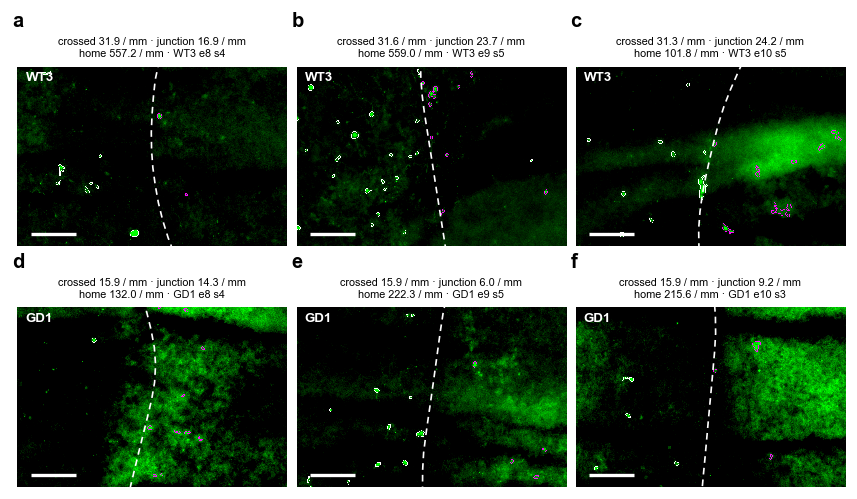

In [11]:
import logging

from scipy import ndimage
from skimage.measure import label as label_objects, regionprops_table
from skimage.morphology import remove_small_holes, remove_small_objects
from skimage.segmentation import find_boundaries

sys.path.insert(0, str(ROOT / "notebooks" / "validation"))
from microscopy_viewer import loaders, junction_analysis as ja   # noqa: E402
import classical_vs_cellpose as cv                                 # noqa: E402

logging.getLogger("tifffile").setLevel(logging.ERROR)

# ---------------------------------------------------------------- Settings for the images
PER_GENOTYPE = 3                 # sections shown per genotype: one per experiment
DISPLAY_PERCENTILES = (50, 99.9) # display range: black at the tissue's median, white near its brightest
ACROSS_UM, ALONG_UM = 600.0, 400.0   # crop: 600 µm across the junction line, 400 µm along it
MARGIN_UM = 60.0                 # read around the crop, so the 20 µm background is not cut at the border
TISSUE_STEP = 8                  # the tissue mask from the nuclear stain at 1/8 (as af488_masks.py)
SCALE_BAR_UM = 100.0
MAGENTA = "#ff00ff"
# ------------------------------------------------------------------------------------------


def representative(g):
    """Per experiment, the section of genotype *g* whose primary outcome lies nearest the genotype's median."""
    part = obs[obs["Genotype"] == g]
    gap = (part[PRIMARY] - part[PRIMARY].median()).abs()
    return [gap[part["Experiment"] == e].idxmin() for e in sorted(part["Experiment"].unique(), key=int)]


def line_midpoint(line):
    """The point halfway along the junction line (by length), and the line's direction there (unit, y-x)."""
    steps = np.r_[0, np.cumsum(np.hypot(*np.diff(line, axis=0).T))]
    mid = np.interp(steps[-1] / 2, steps, np.arange(len(line)))
    i = int(mid)
    point = line[i] + (mid - i) * (line[min(i + 1, len(line) - 1)] - line[i])
    near = (steps > steps[-1] / 2 - 100) & (steps < steps[-1] / 2 + 100)       # the direction over ±100 µm
    direction = line[near][-1] - line[near][0]
    return point, direction / np.linalg.norm(direction)


def recompute_crop(name):
    """AF488 and its kmad5 mask on the crop (+ margin), recomputed with the section's stored threshold."""
    info = json.loads((RUN / "cells" / f"{name}.json").read_text(encoding="utf-8"))
    summary = json.loads((MASKS / name / "summary.json").read_text(encoding="utf-8"))
    voxel, threshold = summary["voxel_um"], summary["thresholds"][METHOD_MASK]
    line = np.asarray(info["line"], dtype=float)                  # µm, (y, x)
    centre, direction = line_midpoint(line)
    vertical = abs(direction[0]) >= abs(direction[1])              # line runs mostly up-down in the image
    half = np.array([ALONG_UM, ACROSS_UM] if vertical else [ACROSS_UM, ALONG_UM]) / 2
    H, W = info["shape_yx"]
    lo = np.maximum(np.floor((centre - half - MARGIN_UM) / voxel).astype(int) // 4 * 4, 0)
    hi = np.minimum(np.ceil((centre + half + MARGIN_UM) / voxel).astype(int), [H, W])
    path = Path(info["file"])
    specs = loaders.load_path(path)
    try:
        names = [str(s.channel_name or s.name) for s in specs]
        af = specs[names.index(CHANNEL)]
        nuclear = specs[names.index(info["nuclear"])]
        small = ja._plane(nuclear, (slice(0, H, TISSUE_STEP), slice(0, W, TISSUE_STEP)))
        plane = ja._plane(af, (slice(lo[0], hi[0]), slice(lo[1], hi[1]))).astype(np.float32)
    finally:
        loaders.release(path)
    tissue_small = cv.tissue_mask(small, step=1)
    rr = np.clip(np.arange(lo[0], hi[0]) // TISSUE_STEP, 0, tissue_small.shape[0] - 1)
    cc = np.clip(np.arange(lo[1], hi[1]) // TISSUE_STEP, 0, tissue_small.shape[1] - 1)
    tissue = tissue_small[rr][:, cc]
    smooth = ndimage.gaussian_filter(plane, cv.SMOOTH_UM / voxel)
    signal = smooth - cv.local_background(smooth, cv.BACKGROUND_UM / voxel)
    mask = remove_small_objects((signal > threshold) & tissue, int(round(cv.MIN_OBJECT_UM2 / voxel ** 2)))
    mask = remove_small_holes(mask, int(round(cv.MAX_HOLE_UM2 / voxel ** 2)))
    labels = label_objects(mask, connectivity=2)
    # trim the margin off
    a = np.round((centre - half) / voxel).astype(int) - lo
    b = a + np.round(2 * half / voxel).astype(int)
    view = (slice(a[0], b[0]), slice(a[1], b[1]))
    origin = (lo + a) * voxel                                       # µm of the crop's top-left pixel
    return dict(name=name, plane=plane[view], tissue=tissue[view], labels=labels[view], origin=origin, voxel=voxel,
                line=line, vertical=vertical, labels_full=labels, origin_full=lo * voxel)


def crossed_labels(crop, o):
    """Labels of the recomputed objects that match a stored crossed object (centroid within 2 µm)."""
    p = pd.DataFrame(regionprops_table(crop["labels_full"], properties=("label", "centroid")))
    if not len(p) or not o["crossed"].any():
        return set(), len(p)
    yx = np.column_stack([p["centroid-0"], p["centroid-1"]]) * crop["voxel"] + crop["origin_full"]
    d, _ = cKDTree(o.loc[o["crossed"], ["Centroid Y (µm)", "Centroid X (µm)"]].to_numpy()).query(yx)
    return set(p.loc[d <= 2.0, "label"]), len(p)


def oriented(crop, name):
    """Image, outlines and line turned so the line runs up-down and AF488's home side is on the left."""
    rgb_scale = np.percentile(crop["plane"][crop["tissue"]] if crop["tissue"].any() else crop["plane"],
                              DISPLAY_PERCENTILES)
    green = np.clip((crop["plane"] - rgb_scale[0]) / (rgb_scale[1] - rgb_scale[0]), 0, 1)
    o = objects[name]
    hit, _ = crossed_labels(crop, o)
    labels = crop["labels"]
    edge = ndimage.binary_dilation(find_boundaries(labels, mode="outer"), iterations=2)   # ~1.5 µm wide, visible in print
    is_crossed = ndimage.binary_dilation(np.isin(labels, list(hit)), iterations=4)
    line = (crop["line"] - crop["origin"]) / crop["voxel"]                # pixels of the crop, (y, x)
    c = cells[name]
    # the far side: the segmented cells inside the crop with away > 0 (sides.py, as the counted objects)
    inside = ((c["y"] - crop["origin"][0]).between(0, labels.shape[0] * crop["voxel"])
              & (c["x"] - crop["origin"][1]).between(0, labels.shape[1] * crop["voxel"]))
    far = c[inside & (c["away"] > 0)][["y", "x"]].to_numpy() - crop["origin"]
    near = c[inside & (c["away"] < 0)][["y", "x"]].to_numpy() - crop["origin"]
    layers = [green, edge & ~is_crossed, edge & is_crossed]
    if not crop["vertical"]:                                               # transpose: the line now runs up-down
        layers = [m.T for m in layers]
        line, far, near = line[:, ::-1], far[:, ::-1], near[:, ::-1]
    width = layers[0].shape[1]
    if len(far) and len(near) and far[:, 1].mean() < near[:, 1].mean():  # mirror: home side on the left
        layers = [m[:, ::-1] for m in layers]
        line = np.column_stack([line[:, 0], width - 1 - line[:, 1]])
    green, white, magenta = layers
    rgb = np.zeros(green.shape + (3,), np.float32)
    rgb[..., 1] = green
    rgb[white] = 1.0
    rgb[magenta] = (1.0, 0.0, 1.0)
    return rgb, line


chosen = {g: representative(g) for g in GENOTYPES}
display(obs.loc[sum(chosen.values(), []), ["Genotype", "slide", PRIMARY, "crossed", "in junction per mm",
                                            "home per mm", "share crossed"]].round(2))
print("genotype medians of crossed per mm:", obs.groupby("Genotype")[PRIMARY].median().round(2).to_dict())

fig, axes = plt.subplots(2, PER_GENOTYPE, figsize=(7.2, 7.2 * 2 * ALONG_UM / ACROSS_UM / PER_GENOTYPE * 1.32))
for row, g in enumerate(GENOTYPES):
    for col, name in enumerate(chosen[g]):
        ax = axes[row, col]
        crop = recompute_crop(name)
        rgb, line = oriented(crop, name)
        ax.imshow(rgb, interpolation="nearest")
        ax.plot(line[:, 1], line[:, 0], color="white", lw=1.0, ls=(0, (4, 3)))
        ax.set_xlim(0, rgb.shape[1] - 1)
        ax.set_ylim(rgb.shape[0] - 1, 0)
        bar = SCALE_BAR_UM / crop["voxel"]
        x0, y0 = rgb.shape[1] * 0.05, rgb.shape[0] * 0.93
        ax.plot([x0, x0 + bar], [y0, y0], color="white", lw=2, solid_capstyle="butt")
        ax.text(0.03, 0.97, g, transform=ax.transAxes, color="white", fontsize=8, fontweight="bold", va="top")
        r = obs.loc[name]
        ax.set_title(f"crossed {r[PRIMARY]:.1f} / mm · junction {r['in junction per mm']:.1f} / mm\n"
                     f"home {r['home per mm']:.1f} / mm · {sections.at[name, 'slide']}", fontsize=6.5)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
panel_letters(axes, x=-0.02, y=1.2)
fig.tight_layout(w_pad=0.4, h_pad=2.0)
save(fig, "figure_3_representative_images")
plt.show()


**Figure 3. Representative junctions of WT3 (a–c) and GD1 (d–f) assembloids.** One section per experiment (a, d: experiment 8; b, e: 9; c, f: 10), each the section nearest its genotype's median of crossed AF488⁺ cells per mm. AF488 in green (display range from the tissue's median to its 99.9th percentile); white dashed line, junction line; outlines, AF488 mask objects (counted AF488⁺ cells), magenta where the object counts as crossed (on the far side of the line, right) and white otherwise. Crops are 600 × 400 µm, centred on the line's midpoint, turned so that the home side is on the left. Above each image: the section's crossed, junction-region and home-side counts per mm, and its slide. Scale bars, 100 µm.

**What it shows (5 Nov 2026).** The crops show what is counted: AF488 cell bodies, most of them on the home side (white outlines; dense in b, sparse in a and f), and fewer, mostly smaller objects past the line (magenta), often within diffuse AF488 signal of the partner organoid (c, d). Only part of a section's crossed objects falls in a crop, because many lie more than 300 µm past the line. Crossed objects are smaller than home-side ones (median area 43 against 53 µm² in WT3 and 39 against 49 µm² in GD1; table under *Sections, sides and counts*), so part of the crossed count is small labelled fragments or processes rather than whole cell bodies, more so in GD1.

## Conclusion (5 Nov 2026)

- **WT3 assembloids have more AF488⁺ cells at and across the junction than GD1 assembloids.** Per mm of junction, WT3 sections had 2.3-fold more AF488⁺ cells that had crossed into the partner organoid (primary outcome; 95 % CI 1.4–3.7, P < 0.001; 614 sections, 36 slides) and 2.3-fold more in the junction region. The difference holds with slides as the unit (2.27-fold, P = 0.008), with any one slide left out, after adjustment for QC status, hand-drawn regions, junction length and section size together (1.72-fold, P = 0.009), and without the 7 sections whose home side is uncertain (2.28-fold).
- **A larger share of WT3's labelled cells crossed.** WT3 had 1.5-fold more AF488⁺ cells on the home side, less than its 2.3-fold excess of crossed cells, and the share of a section's AF488⁺ cells that had crossed was higher in WT3 (0.15 against 0.10, P_Holm = 0.03). The excess of crossed cells in WT3 is thus more than an excess of labelled cells.
- **The crossed cells lie differently.** In WT3 they were 58 µm nearer the organoid edge (also relative to the organoid's local width), but as far past the line as in GD1 (287 against 272 µm, P_Holm = 0.47). WT3 cells that crossed thus stay closer to the surface of the partner organoid. These are 2-D distances in a section, to the nearest edge, which includes cut faces and tears.
- **What changed with the definition of crossed.** Before, an object crossed only when it lay beside the line and 2–300 µm past it, and the side came from the run's AF488⁺ nuclei; now every AF488⁺ object on the far side of the (extended) line counts, and the side comes from the AF488 mask area. The number of crossed objects doubles (11,102 → 22,221; about 40 % of them lie more than 300 µm past the line), and the primary fold rises from **1.86 (1.28–2.71, P = 0.001) to 2.30 (1.44–3.68, P < 0.001)**. Two secondary results change: the share crossed, which before compared cells within 300 µm on either side and was if anything lower in WT3 (0.22 against 0.28, P_Holm = 0.06), is now higher in WT3; and the distance past the line, before 14 µm shorter in WT3 (P_Holm = 0.02), no longer differs. The nearer-the-edge result and the dependence on experiment 9 are unchanged. The new side rule also removes a sign error in 4 GD1 sections where home-side objects had been counted as crossed.
- **Caveats.** (1) The count difference comes mainly from experiment 9 (5.9-fold there; 1.9- and 1.05-fold, not significant, in experiments 8 and 10; 1.37-fold, P = 0.27, without experiment 9). It should be reported per experiment, and confirmed in further batches before it is generalised. (2) The primary outcome, and its definition, were set after exploratory analysis of these data; both definitions are reported. (3) The Junction review kept fewer WT3 than GD1 sections (`01_validation.ipynb`), and the kept WT3 sections were more often QC "ok"; within the QC "ok" sections alone the fold is 1.54 and not significant (P = 0.16), so selection on unmeasured features cannot be excluded. (4) A mask object is a labelled cell body or a fragment of one; crossed objects are smaller on average than home-side ones, and far past the line the mask also picks up bright background patches (`01_validation.ipynb`, Figure 3). (5) In 7 sections the home side is uncertain; leaving them out does not change the result.

## Methods

**Image analysis.** Sections were imaged on a slide scanner (0.325 µm per pixel). The junction between the two organoids of each assembloid was found automatically and every line was screened by eye and redrawn by hand where wrong; a junction region (counting band) was built along it. AF488⁺ cells were counted as objects of a mask of the AF488 channel: the brightest plane over z, smoothed with a Gaussian (σ = 0.5 µm), less its local background (Gaussian, σ = 20 µm), thresholded inside the tissue (Otsu mask of the nuclear stain) at the median + 5 robust standard deviations (1.4826 × median absolute deviation) of the section's tissue; objects < 20 µm² were removed and holes < 10 µm² filled. Each connected object (8-connectivity) was counted as one cell, at its centroid. To give every point of a section a side, the junction line was extended straight past both ends (along the direction of its last 60 µm), and each centroid's signed distance to the extended line was computed. The home side of a section was the side holding more AF488 mask-object area; objects on the other side were *crossed*, all others *home*. Sections in which most AF488⁺ nuclei within 650 µm of the line lay on the other side (7 of 614) were flagged as of uncertain side. Counts were divided by the junction line's length. A crossed object's distance to the organoid edge was that of the nearest segmented nucleus (Cellpose); the local half-width was the 99th percentile of the nuclei's distance to the edge in 25 µm steps past the line, over the whole far side.

**Statistics.** Each outcome was compared between genotypes with a linear mixed model (statsmodels 0.14 `MixedLM`, REML) with genotype and experiment as fixed effects and slide as a random intercept; 95 % confidence intervals are Wald intervals. Counts per mm were modelled as log(1 + y) and are reported as the fold WT3 / GD1 (back-transformed coefficient); the share crossed and distances are reported as differences WT3 − GD1. The primary outcome (crossed AF488⁺ cells per mm of junction) was declared after exploratory analysis and is reported unadjusted; the seven secondary outcomes were adjusted with the Holm method. Robustness of the primary outcome was assessed by leaving out each experiment and each slide in turn, by fitting each experiment alone, by adding section covariates (Junction-review QC status, hand-drawn region, log junction length, log number of segmented cells), by leaving out the sections of uncertain side, and at the slide level (slide means of log(1 + y); Welch's t-test, Mann–Whitney U test, and ordinary least squares with experiment). As a sensitivity analysis the counts were also modelled directly with generalised linear mixed models (slide as a normal random intercept on the link scale; maximum likelihood with adaptive Gauss–Hermite quadrature, 25 nodes per slide; Wald 95 % confidence intervals; `glmm.py`): crossed, junction-region and home-side counts with a negative-binomial (NB2) model, log link and the log junction length as an offset (reported as rate ratios WT3 / GD1; the crossed count also with a Poisson model), and the share crossed as crossed out of crossed + home with a binomial model, logit link and an observation-level random intercept for overdispersion (odds ratio). n = 614 sections (WT3 265, GD1 349) from 36 slides (WT3 17, GD1 19) and three experiments. Mean ± SEM is over sections. Two-sided P < 0.05 was taken as significant. Code: `notebooks/official_analysis/02_biology.ipynb`, `notebooks/official_analysis/sides.py`, `notebooks/dataset/af488_masks.py`, `notebooks/validation/classical_vs_cellpose.py`.

## The per-section table

Every section's outcomes in one table (`sections_table.csv` in the figures folder), also read by the figure builder beside the section browser (`section_browser/figure_builder.html`).

In [12]:
# Every section's outcomes, for re-plotting: FIGURES/sections_table.csv, and the same as sections_table.js beside
# the section browser, where figure_builder.html reads it (with the browser's per-method counts in data.js).
BROWSER = OUT / "section_browser"
PREFIX = "2025_09_26_Asssembloid_"
export = obs.join(sections[["assembloid length (µm)", "QC status", "region by", "sign", "AF488+ nuclei near the line",
                            "share of them at home"]])
export.insert(0, "id", [name.replace(PREFIX, "") for name in export.index])
export = export.reset_index()
export.to_csv(FIGURES / "sections_table.csv", index=False)
meta = {"generated": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "counting method": METHOD_MASK,
        "min crossed cells for the distance outcomes": MIN_EDGE, "min cells for the share crossed": MIN_SHARE}
BROWSER.mkdir(parents=True, exist_ok=True)
(BROWSER / "sections_table.js").write_text(
    "window.BIOLOGY_SECTIONS = " + export.to_json(orient="records", force_ascii=False) + ";\n"
    "window.BIOLOGY_META = " + json.dumps(meta, ensure_ascii=False) + ";\n", encoding="utf-8")
print(f"{len(export)} sections, {export.shape[1]} columns -> {FIGURES / 'sections_table.csv'} and "
      f"{BROWSER / 'sections_table.js'}")


614 sections, 32 columns -> D:\Slidescanner extracted\run_analysis_20261028\figures_official\sections_table.csv and D:\Slidescanner extracted\run_analysis_20261028\section_browser\sections_table.js
